# 05A · NFL movement outcome lab — exploration

**Advanced movement programme — Milestone 05, part A.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-13). No cell has been run by the author.

**Question.** Which NFL movement characteristics can be measured from the tracking trajectories with a physical definition, enough observed windows, and a known dependence on role and opportunity? This notebook builds the play-level measures and describes them. Notebook 05B measures their reliability across independent games and freezes the targets.

**What is measured.** Six families of post-snap measures, all from derived kinematics (Savitzky–Golay positions; never the vendor `s`, `a` or `player_get_off`): O1 robust realized speed · O2 sustained acceleration over 0.5 s and 1.0 s · O3 acceleration conditioned on starting speed · O4 speed gain over fixed windows · O5 speed–acceleration envelope · O6 braking and re-acceleration (exploratory).

**What this notebook is not.** No Combine value is read: the only athlete attributes are the position group and the draft cohort. No outcome is selected here. Observed NFL movement depends on role, alignment, assignment and usage; nothing below is an athlete's physical capability.

**Units.** A frame is a 100 ms sample and never a sample size. A *window* is one eligible player-play post-snap window. The independent unit is the athlete; for reliability it is the athlete-game.

**How to run.** Keep `RUN_MODE = 'smoke'` for a first technical pass (a few games per season; no number is a result), then set `RUN_MODE = 'full'`, restart the kernel and run all cells. The full run scans the NFL tracking frames once (the play table is cached afterwards).

## Configuration

In [1]:
RUN_MODE = 'full'        # 'smoke' | 'full' — smoke reads the first games of each season and writes under .../_sample/nfl_outcomes
FORCE_REBUILD = False     # True = rescan the tracking frames even when the cached play table is current
SAVE_TABLES = True
SAVE_FIGURES = True
SAVE_MODELS = False       # unused: nothing is trained in Milestone 05
SEED = 20261011           # same seed as notebooks 00-04
MAX_ATHLETES = None       # smoke only: None = every tracked athlete of the smoke games; an integer keeps that many (smallest nfl_id)
DEVICE = 'cpu'            # unused here
NUM_WORKERS = 0           # unused here
EXPERIMENT_VERSION = '1'  # version of the NFL outcome definitions (nfl_outcomes.OUTCOMES_VERSION)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import file_fingerprint
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import nfl_outcome_figures as nf
from nflbdb.research.advanced_movement import nfl_outcome_validation
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement.artifacts import NflOutcomeStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS).validate()
if EXPERIMENT_VERSION != no.OUTCOMES_VERSION:
    raise ValueError(f'EXPERIMENT_VERSION = {EXPERIMENT_VERSION!r} but the outcome definitions are version {no.OUTCOMES_VERSION!r}')
c = no.OutcomeConfig(version=EXPERIMENT_VERSION).for_mode(controls)
store = NflOutcomeStore(cfg, controls)     # writes under .../advanced_movement/nfl_outcomes (smoke: .../_sample/nfl_outcomes)
seed_notes = amc.seed_everything(controls.seed)

athlete_ids = None
if controls.smoke and MAX_ATHLETES is not None:
    in_scope = no.NflOutcomeBuilder(cfg, c).athletes().filter(pl.col('position_group').is_in(list(c.positions))).sort('nfl_id')
    athlete_ids = in_scope['nfl_id'].head(int(MAX_ATHLETES)).to_list()
builder = no.NflOutcomeBuilder(cfg, c, limit_games=c.smoke_games if controls.smoke else None, athlete_ids=athlete_ids)

NB05A = '05a_nfl_movement_outcome_eda.ipynb'
PLAYS, VARIANTS, COVERAGE = no.plays_contract(c), no.variants_contract(c), no.coverage_contract(c)
L0, L1 = no.wlab(c.sustain_s[0]), no.wlab(c.sustain_s[-1])     # labels of the 0.5 s and 1.0 s windows
BANDS = [no.blab(lo, hi) for lo, hi in c.speed_bands]
SPEED_MEASURES = ['speed_p90', f'speed_sust{L1}', 'speed_max']
ACCEL_MEASURES = [f'accel_sust{L0}', f'accel_sust{L1}', f'gain{L0}', f'gain{L1}']
BAND_MEASURES = [f'band_acc_{b}' for b in BANDS]
ALL_MEASURES = [*SPEED_MEASURES, f'speed_sust{L0}', *ACCEL_MEASURES, 'gain_d', *BAND_MEASURES, 'decel_sust', 'reaccel_gain']
FIGURES = []

label = 'TECHNICAL CHECK ONLY — a few games per season; no number below is a result' if controls.smoke else 'full population'
scope = f'first {c.smoke_games} games of each season' if controls.smoke else 'every regular-season game with tracking'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {scope} · outcome definitions v{c.version} '
                 f'(definition hash `{no.definition_hash(c)}`) · seed {controls.seed}'))
display(store.describe())

**Run mode: `full`** (full population) · every regular-season game with tracking · outcome definitions v1 (definition hash `dd9610142ae88344`) · seed 20261011

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Input data contracts

Nothing of the warehouse is rebuilt. The frames are read from `silver.game_tracking` in contiguous game batches with the Phase 03 reader; the snap anchor, the side and alignment labels and the quality tier are read from the persisted Phase 03 datasets. A missing input stops the notebook with the name of the build that produces it.

Known limits of these inputs (from the executed Phase 05 P0 audit): the tracking covers the Combine cohorts only (a median of two tracked athletes per play), there are no football rows, and the assignment of an athlete on a play is not recorded. Co-tracking is availability, not a matchup.

In [3]:
SILVER_GOLD = [('silver', 'game_tracking', 'player frames at 10 Hz: game_id, play_id, nfl_id, ts, x, y (vendor s / a / dir / o are dropped)'),
               ('silver', 'games', 'season and week of a game (time order of the windows)'),
               ('silver', 'player_play', 'down / pass_result when recorded at player-play level'),
               ('silver', 'plays', 'down / pass_result when recorded at play level'),
               ('gold', 'dim_athlete', 'position group and draft cohort (stratification only)')]
PHASE_03 = [('nfl_play_anchors', 'snap timestamp per play (season type, has_snap)'),
            ('nfl_player_play_windows', 'side, lined_up_position, penalty flag, in_player_play (window post_snap_all)'),
            ('nfl_trajectory_quality', 'quality tier of the player-play trajectory')]
rows = []
for layer, name, use in SILVER_GOLD:
    files = builder.refs.files(layer, name)
    rows.append({'input': f'{layer}.{name}', 'files': len(files), 'size_mb': round(sum(f.stat().st_size for f in files) / 2 ** 20, 1), 'used_for': use})
for name, use in PHASE_03:
    files = builder.p03.dataset_files(name)
    rows.append({'input': f'gold/phase_03/{name}', 'files': len(files), 'size_mb': round(sum(f.stat().st_size for f in files) / 2 ** 20, 1), 'used_for': use})
inputs = pl.DataFrame(rows)
with pl.Config(tbl_rows=20, fmt_str_lengths=120):
    display(inputs)
absent = inputs.filter(pl.col('files') == 0)['input'].to_list()
if absent:
    raise FileNotFoundError(f'missing inputs {absent}: they are written by the Phase 01 warehouse build and the Phase 03 builds '
                            '(nflbdb.research.kinematic_build, nflbdb.research.nfl_windows); Milestone 05 does not rebuild them')
display(Markdown(f'**Kinematics:** {builder.kcfg.nominal_interval_ms} ms sampling, Savitzky–Golay window {c.primary_smoothing[0]} frames, '
                 f'order {c.primary_smoothing[1]} (primary); sensitivity filters {list(c.sensitivity_smoothing)} on every '
                 f'{c.sensitivity_game_stride}th game of a batch.'))

input,files,size_mb,used_for
str,i64,f64,str
"""silver.game_tracking""",3,532.6,"""player frames at 10 Hz: game_id, play_id, nfl_id, ts, x, y (vendor s / a / dir / o are dropped)"""
"""silver.games""",1,0.0,"""season and week of a game (time order of the windows)"""
"""silver.player_play""",1,3.3,"""down / pass_result when recorded at player-play level"""
"""silver.plays""",1,7.2,"""down / pass_result when recorded at play level"""
"""gold.dim_athlete""",1,0.0,"""position group and draft cohort (stratification only)"""
"""gold/phase_03/nfl_play_anchors""",3,1.9,"""snap timestamp per play (season type, has_snap)"""
"""gold/phase_03/nfl_player_play_windows""",3,87.9,"""side, lined_up_position, penalty flag, in_player_play (window post_snap_all)"""
"""gold/phase_03/nfl_trajectory_quality""",3,6.3,"""quality tier of the player-play trajectory"""


**Kinematics:** 100 ms sampling, Savitzky–Golay window 7 frames, order 2 (primary); sensitivity filters [(5, 2), (9, 2), (11, 3)] on every 2th game of a batch.

## 2 · Synthetic validation

Ten checks on synthetic fixtures with a known answer (no warehouse access): window construction and units, the snap anchor, segment boundaries and filter-edge frames, speed-band definitions, the braking rule, the real smoothing chain on an analytic trajectory, player-play de-duplication and time order, missingness, the absence of any Combine source, and the artifact area. Every row must read `PASS`; the cell stops otherwise.

In [4]:
validation_report = nfl_outcome_validation.run_all(nfl_outcome_validation.CHECKS_05A)
with pl.Config(tbl_rows=30, fmt_str_lengths=400, tbl_width_chars=200):
    display(validation_report)
nfl_outcome_validation.assert_all_passed(validation_report)

09:00:19 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_DICTIONARY] computing (never run)
09:00:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:NFL_DICTIONARY] nfl_outcome_dictionary: 21 rows → C:/Users/myben/AppData/Local/Temp/tmpq1yagyqy/warehouse/gold/advanced_movement/_sample/nfl_outcomes/nfl_outcome_dictionary.parquet
09:00:19 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_DICTIONARY] restored from cache (current)
09:00:19 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_DICTIONARY] computing (parameters or upstream inputs changed)
09:00:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:NFL_DICTIONARY] nfl_outcome_dictionary: 21 rows → C:/Users/myben/AppData/Local/Temp/tmpq1yagyqy/warehouse/gold/advanced_movement/_sample/nfl_outcomes/nfl_outcome_dictionary.parquet


check,status,detail
str,str,str
"""window_construction_and_units""","""PASS""","""constant 2 yd/s²: sustained acceleration 2.000 yd/s², gain 1.00 yd/s per 0.5 s and 2.00 per 1.0 s; 5 yd at 5 yd/s takes 1.0 s; the phase-space histogram keeps all 60 frames"""
"""snap_anchor_excludes_pre_snap""","""PASS""","""40 post-snap frames kept, 20 pre-snap frames at 11 yd/s ignored (peak 3.0 yd/s); the play without a snap tag has no row"""
"""segment_boundaries""","""PASS""","""no window spans a segment break; a 30-frame segment gives 19 start frames with edge windows excluded and 25 with them kept; an 8-frame segment has no sustained measure (kept missing)"""
"""speed_band_definitions""","""PASS""","""bands are half-open [lo, hi) on the STARTING speed: 20 start frames per 2 yd/s band on a 1 yd/s² ramp, band acceleration 1.0 yd/s²; a band visited on fewer than 3 frames stays missing"""
"""braking_reacceleration_rule""","""PASS""","""a 4 yd/s² braking from 8 yd/s followed by 3 yd/s² gives decel 4.0 yd/s² and a re-acceleration gain of 1.5 yd/s; a play without a qualifying braking has no re-acceleration value"""
"""smoothing_behaviour""","""PASS""","""the real segmentation + Savitzky–Golay chain returns 2.000 yd/s² on noise-free quadratic motion; with 0.02 yd position noise the acceleration error SD is 1.04 (5 frames) against 0.18 yd/s² (9 frames), and the play maximum of the 0.5 s mean reads 2.37 against 2.11 (a maximum rises with noise)"""
"""player_play_deduplication_and_order""","""PASS""","""10 player-plays stay 10 rows with duplicated labels; the first failing rule is the exclusion reason; eligible windows and games are numbered in time order across seasons; the funnel is monotone"""
"""missingness_and_composites""","""PASS""","""undefined windows are excluded from the statistic and counted as excluded (240 of 1,920, opportunity rate 0.875); an athlete lacking one speed band has no envelope value instead of an average"""
"""no_combine_access""","""PASS""","""3 module files name no Combine table or representation; a Combine-prefixed column stops the engine and the freeze; the screening, proposal and freeze functions take NFL evidence only"""


## 3 · Candidate outcomes and exposure rules

Each candidate is an athlete statistic (mean, median, p90 or p95 over the athlete's eligible windows) of one play measure. The play measure is itself a robust summary of the post-snap frames of one player-play: a maximum over *fixed windows* (0.5 s, 1.0 s, 5 yd), never a single-frame peak — the single-frame peak is kept as a reference row only.

Three distinctions the table keeps explicit:

- **Speed change against acceleration.** `gain` is a speed difference over a window (first derivative of position only); `accel_sust` is the mean of d|v|/dt over the same window (second derivative). They estimate nearly the same quantity and differ in filter noise.
- **Opportunity against movement.** An outcome is defined only on windows where its situation occurred (a speed band visited, a qualifying braking). How often that happens is reported as coverage; the outcome value is conditional on it.
- **Role.** `candidate` outcomes can be frozen in 05B; `component` rows are the points of the O5 envelope; `reference` and `exploratory` rows are never targets.

In [5]:
dictionary_preview = no.outcome_dictionary(c)
display(Markdown(f'**{dictionary_preview.height} outcome definitions** (unit: definition; key `outcome_id`)'))
with pl.Config(tbl_rows=40, fmt_str_lengths=170, tbl_width_chars=240):
    display(dictionary_preview.select('outcome_id', 'role', 'unit', 'athlete_statistic', 'starting_speed_range', 'formula'))
first = dictionary_preview.row(0, named=True)
display(Markdown('**Rules common to every outcome**\n\n'
                 f'- Context: {first["applicable_context"]}\n'
                 f'- Quality: {first["quality_requirements"]}\n'
                 f'- Exposure: {first["min_exposure"]}\n'
                 f'- Smoothing: {first["smoothing"]}\n'
                 f'- Direction: {first["direction_note"]}'))

**21 outcome definitions** (unit: definition; key `outcome_id`)

outcome_id,role,unit,athlete_statistic,starting_speed_range,formula
str,str,str,str,str,str
"""O1.speed_sust05_p90""","""candidate""","""yd/s""","""p90""","""any""","""p90 over eligible windows of max_t mean(speed[t, t + 0.5 s])"""
"""O1.speed_sust10_p90""","""candidate""","""yd/s""","""p90""","""any""","""p90 over eligible windows of max_t mean(speed[t, t + 1 s])"""
"""O1.speed_p90_mean""","""candidate""","""yd/s""","""mean""","""any""","""mean over eligible windows of the 90th percentile of post-snap frame speeds"""
"""O1.speed_max_p95""","""reference""","""yd/s""","""p95""","""any""","""p95 over eligible windows of max_t speed[t]"""
"""O2.accel_sust05_p90""","""candidate""","""yd/s²""","""p90""","""any""","""p90 over eligible windows of max_t mean(a_tan[t, t + 0.5 s]), a_tan = d|v|/dt"""
"""O2.accel_sust10_p90""","""candidate""","""yd/s²""","""p90""","""any""","""p90 over eligible windows of max_t mean(a_tan[t, t + 1 s]), a_tan = d|v|/dt"""
"""O2.accel_sust05_mean""","""candidate""","""yd/s²""","""mean""","""any""","""mean over eligible windows of max_t mean(a_tan[t, t + 0.5 s])"""
"""O3.band_acc_v0_2_mean""","""candidate""","""yd/s²""","""mean""","""[0, 2) yd/s""","""mean over eligible windows of mean_t [(speed(t + 0.5 s) − speed(t)) / 0.5 s] over start frames with speed in [0, 2) and a positive change (≥ 3 such frames)"""
"""O3.band_acc_v2_4_mean""","""candidate""","""yd/s²""","""mean""","""[2, 4) yd/s""","""mean over eligible windows of mean_t [(speed(t + 0.5 s) − speed(t)) / 0.5 s] over start frames with speed in [2, 4) and a positive change (≥ 3 such frames)"""


**Rules common to every outcome**

- Context: season types REG; post-snap frames of plays with a snap tag; context cell = position group × alignment × play class (adjusted variant)
- Quality: quality tier in ['A', 'B']; ≥ 15 valid post-snap frames; not nullified by penalty; windows touching filter-edge frames excluded
- Exposure: ≥ 50 eligible windows (primary threshold; grid [20, 50, 100, 200])
- Smoothing: Savitzky–Golay window 7 frames, order 2 (KinematicsConfig v1)
- Direction: larger = more of the measured movement was observed; no claim that larger is better

## 4 · Play measures (one scan of the tracking frames)

For every game batch: segment the trajectories, compute the kinematics on whole trajectories (so the snap never creates a filter edge), keep the post-snap frames, and reduce them to one row per player-play. The alternative filters and the boundary-inclusive variant are computed on a subset of games in the same pass. The result is cached: a rerun restores it unless a parameter or an input file changed.

In [6]:
built = store.build('NFL_PLAYS', [PLAYS, VARIANTS, no.PHASE_SPACE, no.FUNNEL], builder.compute, params=builder.params(),
                    files=builder.input_files())
plays, variants, phase, funnel = (built[k.name] for k in (PLAYS, VARIANTS, no.PHASE_SPACE, no.FUNNEL))
no.assert_no_combine_columns(plays, 'play table')
el = plays.filter(pl.col('eligible'))
POSITIONS = sorted(el['position_group'].unique().to_list())
n_athletes = el['nfl_id'].n_unique()
n_games = el.select(pl.struct('nfl_id', 'game_id').n_unique()).item() if el.height else 0
display(Markdown(f'**{plays.height:,} tracked player-plays with a snap tag → {el.height:,} eligible windows of {n_athletes} athletes '
                 f'in {n_games:,} athlete-games** · {variants["variant"].n_unique() if variants.height else 0} measure variants on '
                 f'{variants.select(pl.struct("game_id", "play_id", "nfl_id").n_unique()).item() if variants.height else 0:,} player-plays'))
if not el.height:
    raise RuntimeError('no eligible window: check the funnel table below and the Phase 03 inputs')

09:00:20 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_PLAYS] computing (never run)
09:00:20 | INFO    | nflbdb.research.advanced_movement.nfl_outcomes | [nfl_outcomes] season 2023 batch 2/14 (games 2023081956–2023090700): 5,435 frames, 73 player-plays (0s)
09:00:21 | INFO    | nflbdb.research.advanced_movement.nfl_outcomes | [nfl_outcomes] season 2023 batch 3/14 (games 2023091000–2023091708): 221,167 frames, 3,089 player-plays (2s)
09:00:22 | INFO    | nflbdb.research.advanced_movement.nfl_outcomes | [nfl_outcomes] season 2023 batch 4/14 (games 2023091709–2023100101): 193,669 frames, 2,719 player-plays (3s)
09:00:23 | INFO    | nflbdb.research.advanced_movement.nfl_outcomes | [nfl_outcomes] season 2023 batch 5/14 (games 2023100102–2023100811): 234,212 frames, 3,243 player-plays (4s)
09:00:25 | INFO    | nflbdb.research.advanced_movement.nfl_outcomes | [nfl_outcomes] season 2023 batch 6/14 (games 2023100900–2023102207): 253,170 frames, 3,557 player-pl

**251,089 tracked player-plays with a snap tag → 242,043 eligible windows of 401 athletes in 7,891 athlete-games** · 4 measure variants on 130,279 player-plays

## 5 · Cohort and eligible windows

The denominators of everything that follows. The eligibility rules are applied in a fixed order and the first failing rule is recorded; nothing is imputed. The exposure distribution matters as much as the counts: athletes differ in eligible windows by an order of magnitude, and the thresholds of the reliability study remove the least-exposed athletes whatever their movement.

**Eligibility funnel** (unit: tracked player-play with a snap tag; athletes and athlete-games beside it)

stage,stage_order,n_player_plays,n_athletes,n_athlete_games
str,i64,i64,i64,i64
"""tracked_with_snap""",0,251089,401,7900
"""position_in_scope""",1,251089,401,7900
"""not_nullified_by_penalty""",2,242328,401,7892
"""usable_quality_tier""",3,242090,401,7892
"""eligible""",4,242043,401,7891


position_group,n_player_plays,n_athletes,n_athlete_games
str,i64,i64,i64
"""ALL""",242043,401,7891
"""DB""",63914,96,1744
"""DL""",50363,98,1953
"""OL""",82806,91,1640
"""TE""",8124,33,681
"""WR""",36836,83,1873


**Eligible windows by position group and season** (unit: window; athletes and athlete-games are the independent units)

position_group,season,athletes,athlete_games,windows
str,i64,u32,u32,u32
"""DB""",2023,27,242,7802
"""DB""",2024,60,632,23218
"""DB""",2025,84,870,32894
"""DL""",2023,30,308,7132
"""DL""",2024,57,646,16620
"""DL""",2025,90,999,26611
"""OL""",2023,25,264,14245
"""OL""",2024,54,555,27273
"""OL""",2025,82,821,41288


position_group,athletes,median_windows,median_games,athletes_ge_20,athletes_ge_50,athletes_ge_100,athletes_ge_200
str,u32,f64,f64,u32,u32,u32,u32
"""DB""",96,416.5,15.0,89,78,71,65
"""DL""",98,289.5,17.0,95,88,76,65
"""OL""",91,747.0,15.0,85,77,69,65
"""TE""",33,183.0,17.0,29,23,21,16
"""WR""",83,292.0,17.0,78,70,63,53


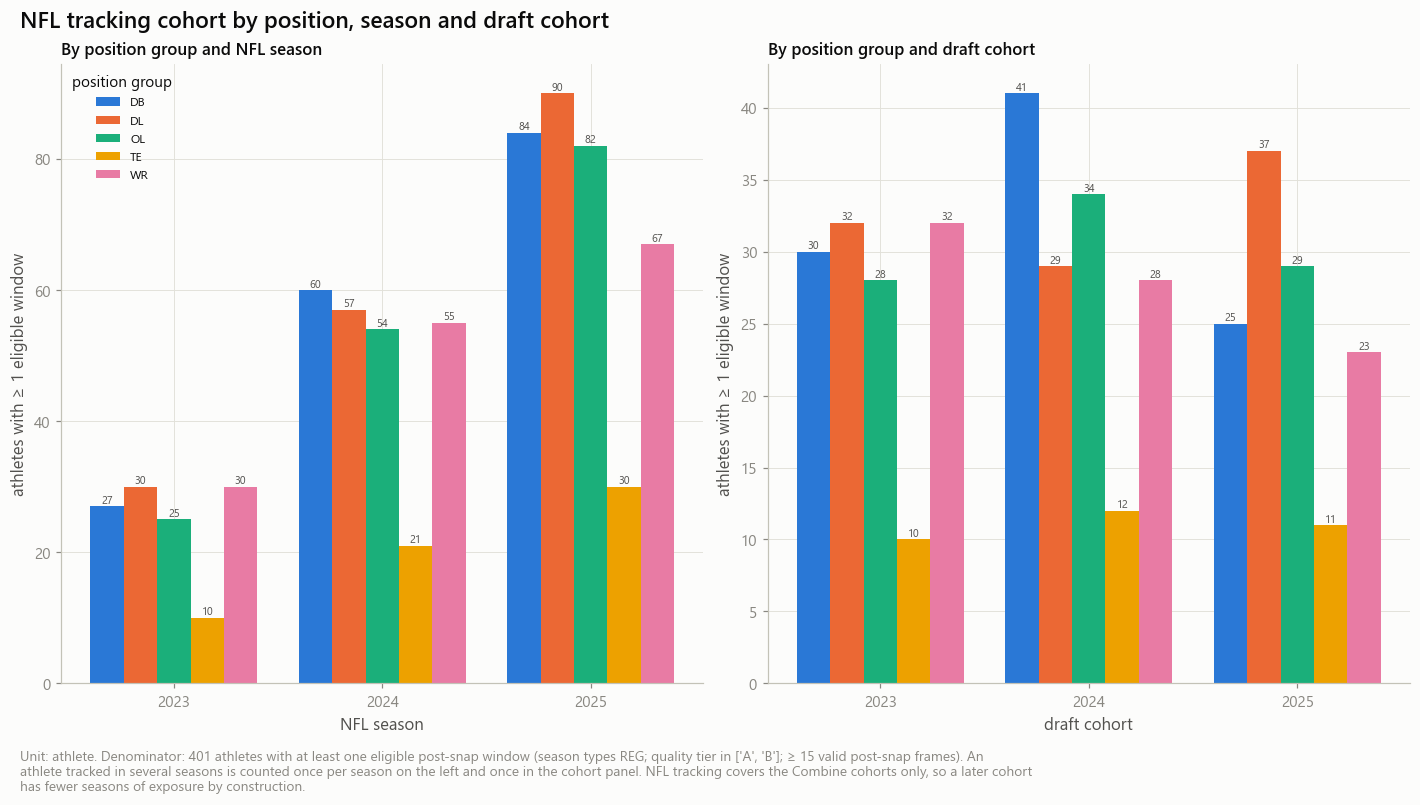

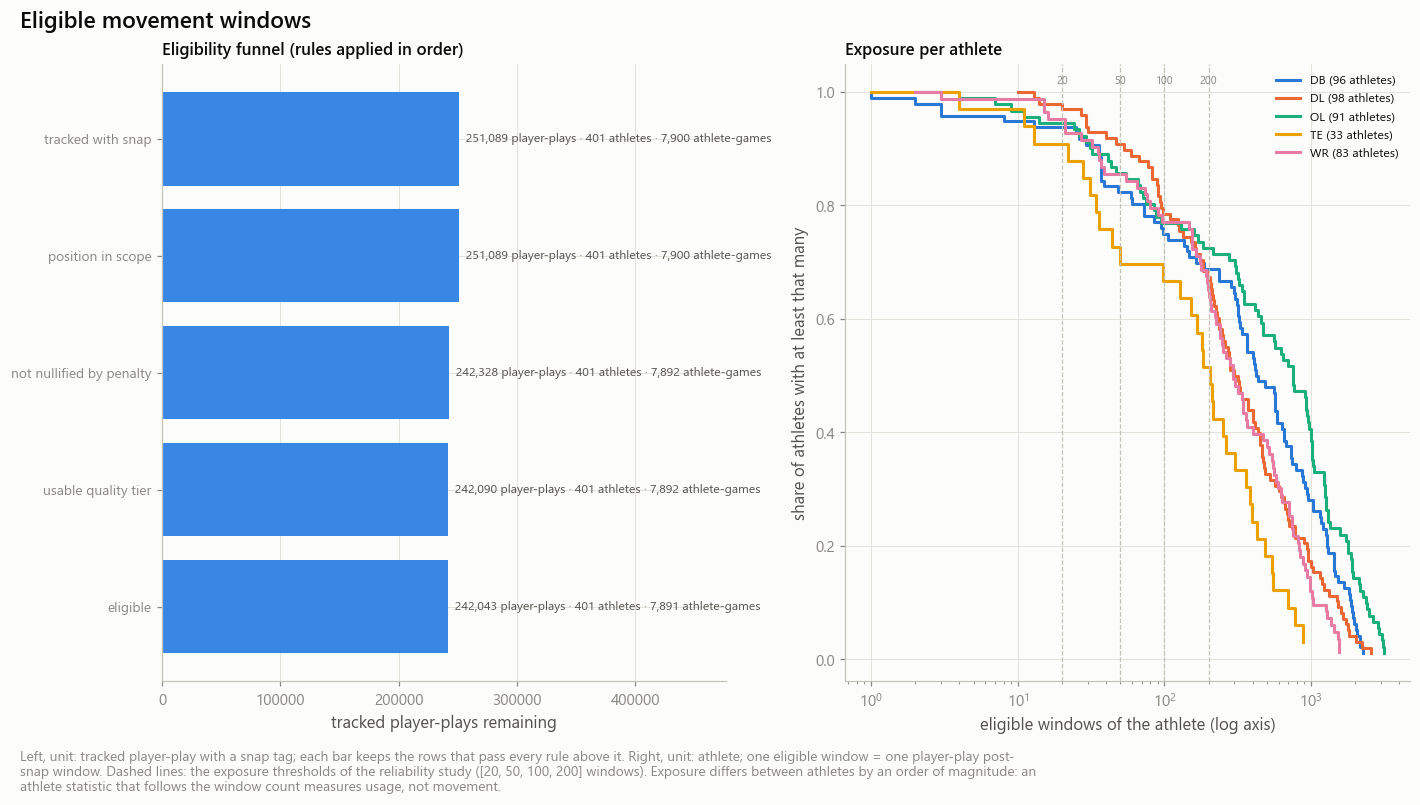

In [7]:
display(Markdown('**Eligibility funnel** (unit: tracked player-play with a snap tag; athletes and athlete-games beside it)'))
with pl.Config(tbl_rows=40):
    display(funnel.filter(pl.col('position_group') == no.ALL).sort('stage_order').drop('position_group'))
    display(funnel.filter(pl.col('stage') == 'eligible').sort('position_group').drop('stage', 'stage_order'))
display(Markdown('**Eligible windows by position group and season** (unit: window; athletes and athlete-games are the independent units)'))
by_season = (el.group_by('position_group', 'season')
             .agg(pl.col('nfl_id').n_unique().alias('athletes'), pl.struct('nfl_id', 'game_id').n_unique().alias('athlete_games'),
                  pl.len().alias('windows')).sort('position_group', 'season'))
per_athlete = el.group_by('position_group', 'nfl_id').agg(pl.len().alias('n'), pl.col('game_id').n_unique().alias('g'))
exposure = (per_athlete.group_by('position_group')
            .agg(pl.len().alias('athletes'), pl.col('n').median().alias('median_windows'), pl.col('g').median().alias('median_games'),
                 *[(pl.col('n') >= t).sum().alias(f'athletes_ge_{t}') for t in c.min_windows_grid]).sort('position_group'))
with pl.Config(tbl_rows=40):
    display(by_season)
    display(exposure)
store.show(nf.plot_cohort(plays, c), 'AM05A_01_nfl_tracking_cohort', {'by_season': by_season}, publication=True,
           source='nfl_play_movement', n=f'{n_athletes} athletes')
store.show(nf.plot_window_counts(funnel, plays, c), 'AM05A_02_eligible_movement_windows', {'funnel': funnel, 'exposure': exposure},
           source='nfl_window_funnel, nfl_play_movement', n=f'{el.height} windows, {n_athletes} athletes')
FIGURES += ['AM05A_01_nfl_tracking_cohort', 'AM05A_02_eligible_movement_windows']

## 6 · Speed and acceleration distributions by position

Play-level distributions, by position group. Read the single-frame peak against the sustained and percentile measures: the gap between them is what one frame adds. The plausibility column counts windows beyond the project's physical limits for derived speed and acceleration (`KinematicsConfig.max_speed_yds`, `max_accel_yds2`); a sustained mean beyond the single-frame limit is not a movement.

Position groups differ in level for reasons of role (a lineman rarely reaches the speeds a receiver runs). Every athlete comparison in 05B is therefore made inside the position group.

**Play measures by position group** (unit: eligible window with the measure defined; athletes beside it)

measure,unit,position_group,windows,athletes,p10,median,p90,p99,max,share_above_limit
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64
"""accel_sust05""","""yd/s²""","""DB""",63767,96,2.297,3.647,5.117,6.382,8.597,0.000
"""accel_sust05""","""yd/s²""","""DL""",50316,98,1.949,3.277,4.673,5.537,7.987,0.000
"""accel_sust05""","""yd/s²""","""OL""",82717,91,1.591,2.483,3.495,4.381,7.408,0.000
"""accel_sust05""","""yd/s²""","""TE""",8124,33,3.008,4.208,5.069,5.889,7.496,0.000
"""accel_sust05""","""yd/s²""","""WR""",36836,83,3.425,4.852,5.702,6.525,8.618,0.000
"""accel_sust10""","""yd/s²""","""DB""",63592,96,1.855,3.019,4.234,5.079,6.201,0.000
"""accel_sust10""","""yd/s²""","""DL""",50230,98,1.410,2.605,3.794,4.527,5.884,0.000
"""accel_sust10""","""yd/s²""","""OL""",82485,91,1.150,1.949,2.835,3.589,4.977,0.000
"""accel_sust10""","""yd/s²""","""TE""",8124,33,2.528,3.687,4.431,4.938,5.647,0.000


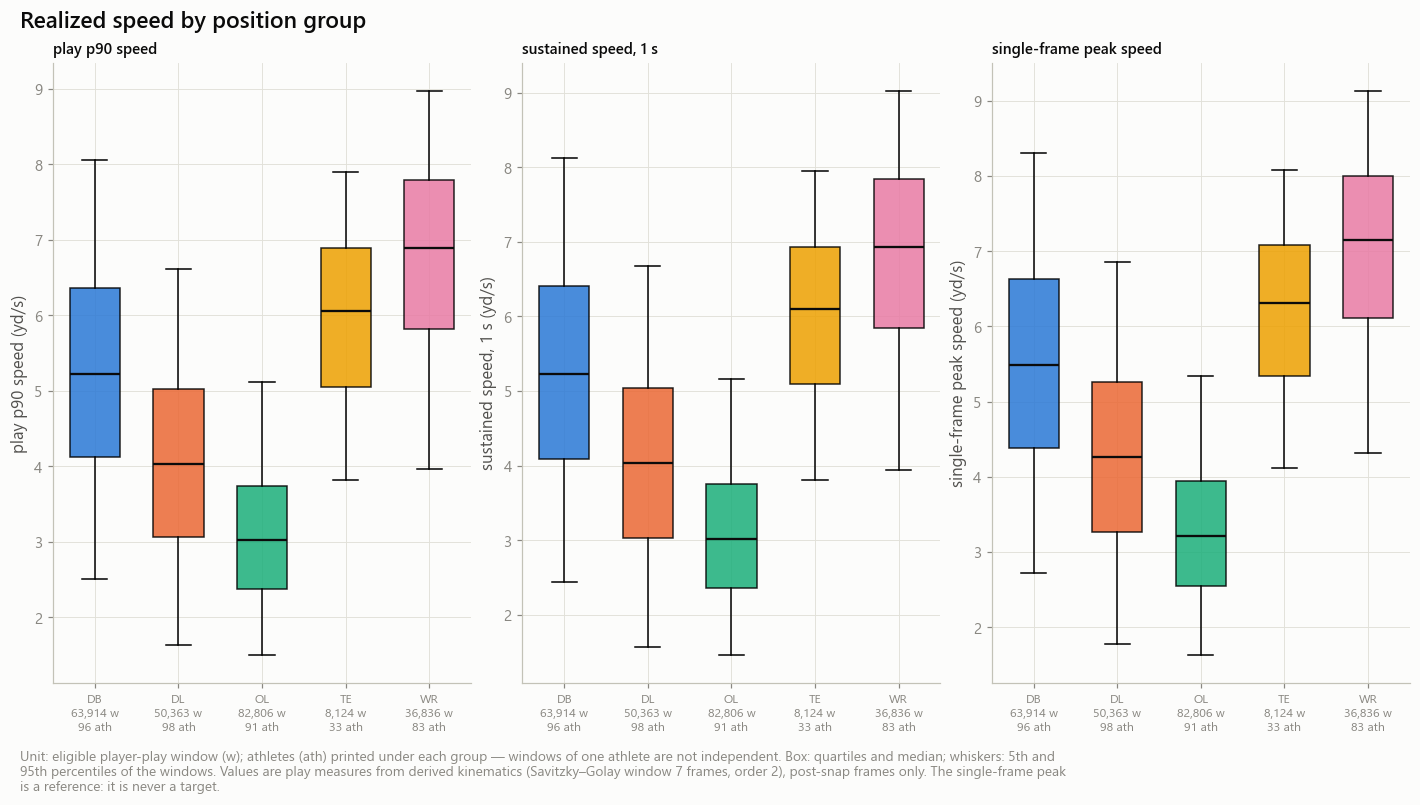

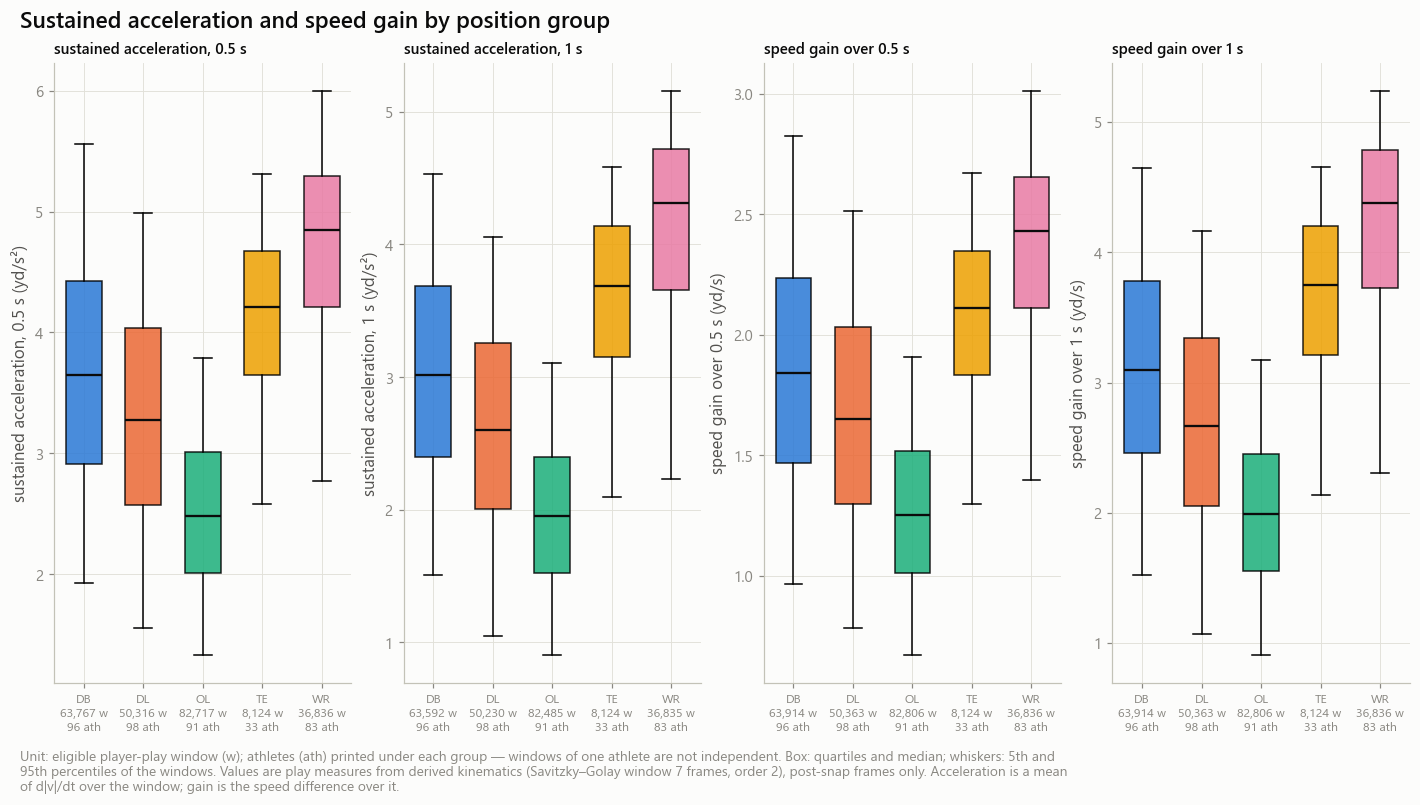

In [8]:
LIMITS = {**{k: float(builder.kcfg.max_speed_yds) for k in [*SPEED_MEASURES, f'speed_sust{L0}']},
          **{k: float(builder.kcfg.max_accel_yds2) for k in [f'accel_sust{L0}', f'accel_sust{L1}', 'decel_sust', *BAND_MEASURES]}}
summary = nf.measure_summary(plays, ALL_MEASURES, LIMITS)
display(Markdown('**Play measures by position group** (unit: eligible window with the measure defined; athletes beside it)'))
with pl.Config(tbl_rows=120, float_precision=3):
    display(summary)
if controls.save_tables:
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    summary.write_csv(store.tables_dir / 'nfl_play_measure_summary.csv')
store.show(nf.plot_measure_distributions(plays, SPEED_MEASURES, c, 'Realized speed by position group',
                                         'The single-frame peak is a reference: it is never a target.'),
           'AM05A_03_speed_distributions_by_position', {'summary': summary.filter(pl.col('measure').is_in(SPEED_MEASURES))},
           publication=True, source='nfl_play_movement', n=f'{el.height} windows, {n_athletes} athletes')
store.show(nf.plot_measure_distributions(plays, ACCEL_MEASURES, c, 'Sustained acceleration and speed gain by position group',
                                         'Acceleration is a mean of d|v|/dt over the window; gain is the speed difference over it.'),
           'AM05A_04_acceleration_distributions_by_position', {'summary': summary.filter(pl.col('measure').is_in(ACCEL_MEASURES))},
           publication=True, source='nfl_play_movement', n=f'{el.height} windows, {n_athletes} athletes')
FIGURES += ['AM05A_03_speed_distributions_by_position', 'AM05A_04_acceleration_distributions_by_position']

## 7 · Speed–acceleration phase space

The conditional distribution of the tangential acceleration given the speed, per position group: how much speed is still being gained at each speed in observed play. This is the empirical basis of O3 (acceleration by starting-speed band) and O5 (envelope). It is a density of frames, so it carries no sample size, and it describes what the position did in its role.

**Post-snap frames in the phase space** (a frame is not an independent observation)

position_group,n_frames
str,i64
"""DB""",4107244
"""DL""",3224025
"""OL""",5297158
"""TE""",541355
"""WR""",2422823


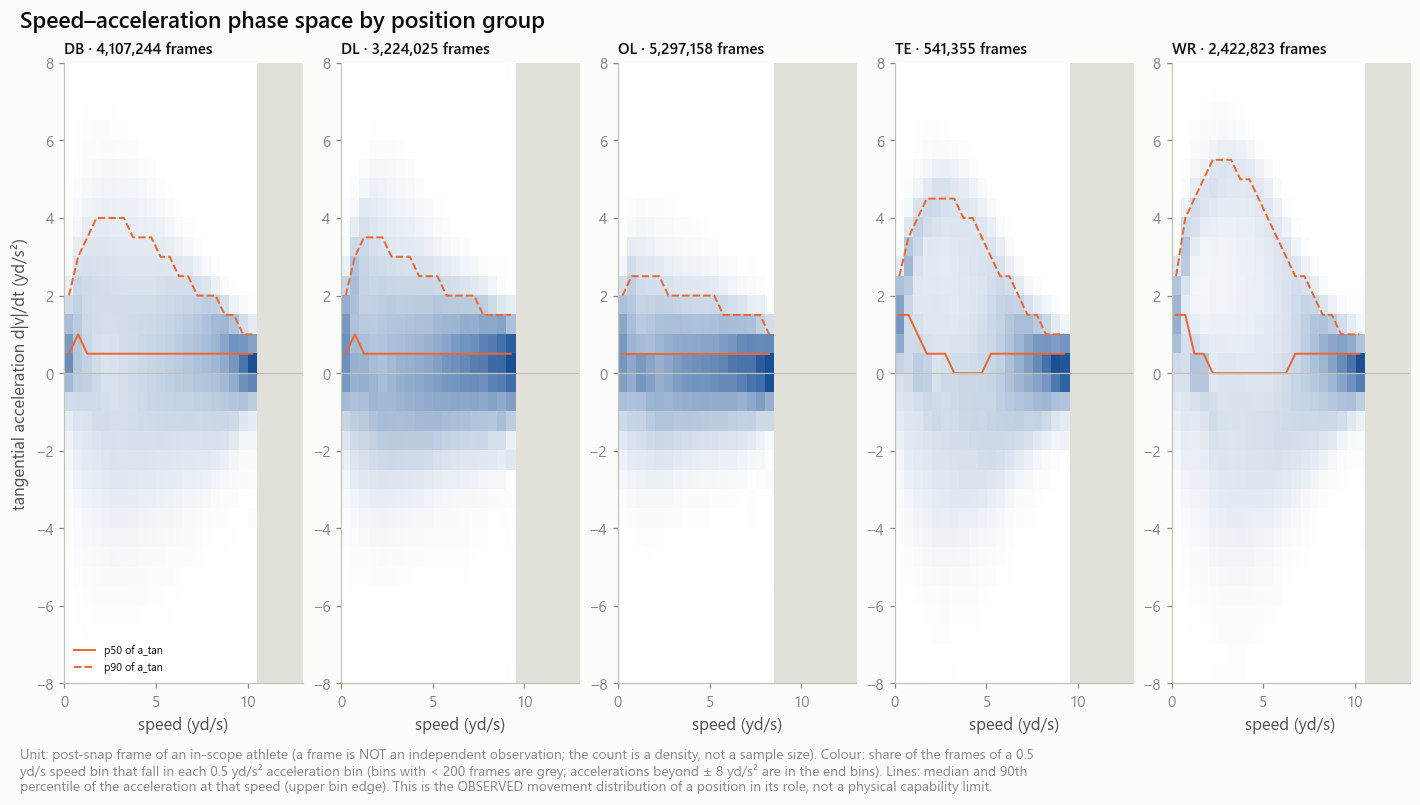

In [9]:
frames_by_position = phase.group_by('position_group').agg(pl.col('n_frames').sum()).sort('position_group')
display(Markdown('**Post-snap frames in the phase space** (a frame is not an independent observation)'))
display(frames_by_position)
store.show(nf.plot_phase_space(phase, c), 'AM05A_05_speed_acceleration_phase_space', {'phase_space': phase}, publication=True,
           source='nfl_phase_space', n=f'{int(phase["n_frames"].sum()) if phase.height else 0} frames, {n_athletes} athletes')
FIGURES += ['AM05A_05_speed_acceleration_phase_space']

## 8 · Starting-speed coverage and alignment

Two questions about opportunity. First, which starting-speed bands does each position actually visit while accelerating, and for how many athletes is a band observed often enough? A band that is not feasible for a position is not a target there. Second, how are the eligible windows spread over the vendor alignments, and how far does the level of a measure move with the alignment? Alignment is an observed label; the assignment is not in the data.

**Share of eligible windows with ≥ 3 accelerating start frames in each starting-speed band** (unit: window)

position_group,eligible_windows,share_v0_2,share_v2_4,share_v4_6,share_v6_8
str,u32,f64,f64,f64,f64
"""DB""",63914,0.959,0.949,0.693,0.272
"""DL""",50363,0.991,0.878,0.422,0.086
"""OL""",82806,0.996,0.789,0.153,0.012
"""TE""",8124,0.966,0.977,0.863,0.450
"""WR""",36836,0.956,0.961,0.883,0.652


**Alignments by position group, with the level of `speed_sust10`** (unit: window; 41 alignment rows)

position_group,lined_up_position,windows,athletes,mean,sd
str,str,u32,u32,f64,f64
"""DB""","""CB""",27435,85,5.119,1.813
"""DB""","""HIGH_SAFETY""",18491,73,5.489,1.540
"""DB""","""SLOT_CB""",10643,87,5.412,1.636
"""DB""","""OLB""",4705,81,4.831,1.864
"""DB""","""MLB""",1194,66,4.998,2.039
"""DB""","""EDGE""",1099,60,4.499,1.867
"""DB""","""BOX_SAFETY""",217,47,5.612,1.685
"""DB""","""INTERIOR_LINE""",104,22,4.731,2.205
"""DL""","""EDGE""",27691,93,4.351,1.501


**Play class and side** (play class groups the vendor `pass_result` code; the meaning of the empty code is inferred, not confirmed)

position_group,play_class,side,windows,athletes
str,str,str,u32,u32
"""DB""","""no_pass""","""defense""",24203,91
"""DB""","""no_pass""","""offense""",12,1
"""DB""","""pass""","""defense""",34956,92
"""DB""","""pass""","""offense""",14,1
"""DB""","""sack_or_scramble""","""defense""",4729,86
"""DL""","""no_pass""","""defense""",21210,98
"""DL""","""no_pass""","""offense""",1,1
"""DL""","""pass""","""defense""",25788,98
"""DL""","""sack_or_scramble""","""defense""",3364,95


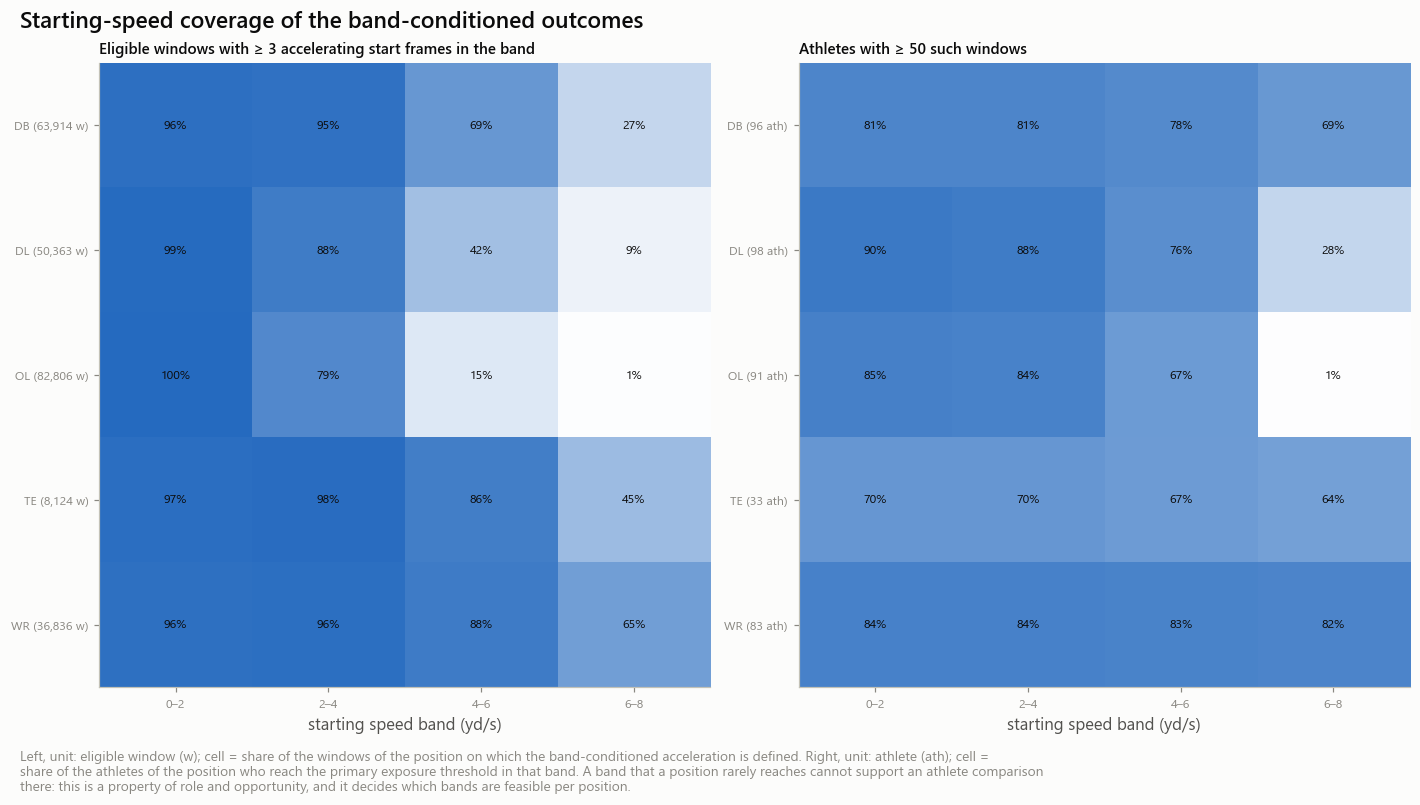

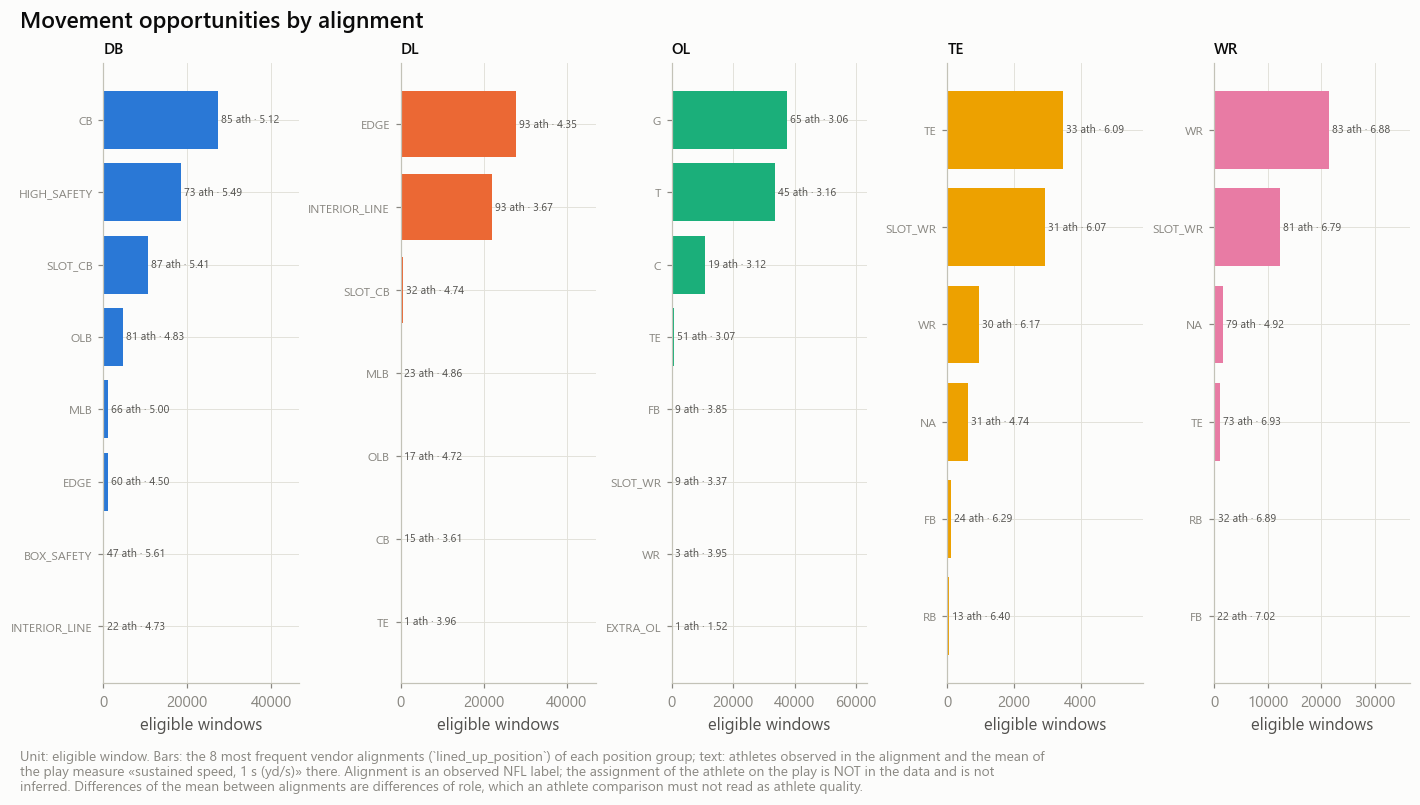

In [10]:
band_cover = (el.group_by('position_group')
              .agg(pl.len().alias('eligible_windows'), *[pl.col(f'band_acc_{b}').is_not_null().mean().alias(f'share_{b}') for b in BANDS])
              .sort('position_group'))
display(Markdown(f'**Share of eligible windows with ≥ {c.min_band_starts} accelerating start frames in each starting-speed band** (unit: window)'))
with pl.Config(float_precision=3):
    display(band_cover)
ALIGN_MEASURE = f'speed_sust{L1}'
alignment = (el.with_columns(pl.col('lined_up_position').fill_null('NA')).group_by('position_group', 'lined_up_position')
             .agg(pl.len().alias('windows'), pl.col('nfl_id').n_unique().alias('athletes'), pl.col(ALIGN_MEASURE).mean().alias('mean'),
                  pl.col(ALIGN_MEASURE).std().alias('sd')).sort(['position_group', 'windows'], descending=[False, True]))
display(Markdown(f'**Alignments by position group, with the level of `{ALIGN_MEASURE}`** (unit: window; {alignment.height} alignment rows)'))
with pl.Config(tbl_rows=60, float_precision=3):
    display(alignment.filter(pl.col('windows') >= c.min_cell_windows))
play_class = el.group_by('position_group', 'play_class', 'side').agg(pl.len().alias('windows'), pl.col('nfl_id').n_unique().alias('athletes')).sort('position_group', 'play_class', 'side')
display(Markdown('**Play class and side** (play class groups the vendor `pass_result` code; the meaning of the empty code is inferred, not confirmed)'))
with pl.Config(tbl_rows=60):
    display(play_class)
store.show(nf.plot_start_speed_coverage(plays, c), 'AM05A_06_starting_speed_coverage', {'band_cover': band_cover},
           source='nfl_play_movement', n=f'{el.height} windows, {n_athletes} athletes')
store.show(nf.plot_alignment(plays, ALIGN_MEASURE, c), 'AM05A_07_movement_opportunities_by_alignment', {'alignment': alignment},
           source='nfl_play_movement', n=f'{el.height} windows, {n_athletes} athletes')
FIGURES += ['AM05A_06_starting_speed_coverage', 'AM05A_07_movement_opportunities_by_alignment']

## 9 · Athlete-level outcomes, coverage and opportunity

The candidate outcomes are now computed per athlete on all eligible windows, with their coverage. For every outcome and position the coverage table records the athletes tracked, the athletes with a value, the athletes at each exposure threshold, the windows, the athlete-games, the eligible plays on which the outcome is *not* defined, and the opportunity rate. Its last columns give the within-position rank correlation between the athlete value and the logarithm of the window count: an outcome that follows usage shows there.

Tracked exposure and observed opportunity are different things. An athlete can be tracked on many plays and rarely be in the situation an outcome needs.

09:02:17 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_ATHLETE] computing (never run)
09:02:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:NFL_ATHLETE] nfl_outcome_dictionary: 21 rows → warehouse/gold/advanced_movement/nfl_outcomes/nfl_outcome_dictionary.parquet
09:02:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:NFL_ATHLETE] nfl_athlete_outcomes: 8,359 rows → warehouse/gold/advanced_movement/nfl_outcomes/nfl_athlete_outcomes.parquet
09:02:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:NFL_ATHLETE] nfl_athlete_game_outcomes: 154,239 rows → warehouse/gold/advanced_movement/nfl_outcomes/nfl_athlete_game_outcomes.parquet
09:02:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:NFL_ATHLETE] nfl_outcome_coverage: 126 rows → warehouse/gold/advanced_movement/nfl_outcomes/nfl_outcome_coverage.parquet


**Coverage, all positions** (unit: athlete; primary exposure threshold 50 windows)

outcome_id,n_athletes_tracked,n_athletes_any,n_athletes_ge_50,n_windows,n_athlete_games,n_plays_undefined,opportunity_rate,rho_value_log_windows
str,i64,i64,i64,i64,i64,i64,f64,f64
"""O1.speed_sust05_p90""",401,401,336,242043,7891,0,1.000,-0.085
"""O1.speed_sust10_p90""",401,401,336,242043,7891,0,1.000,-0.090
"""O1.speed_p90_mean""",401,401,336,242043,7891,0,1.000,-0.086
"""O1.speed_max_p95""",401,401,336,242043,7891,0,1.000,-0.058
"""O2.accel_sust05_p90""",401,401,336,241760,7891,283,0.999,0.126
"""O2.accel_sust10_p90""",401,401,336,241266,7886,777,0.997,0.086
"""O2.accel_sust05_mean""",401,401,336,241760,7891,283,0.999,0.110
"""O3.band_acc_v0_2_mean""",401,401,336,236756,7882,5287,0.978,-0.017
"""O3.band_acc_v2_4_mean""",401,400,333,213542,7831,28501,0.882,0.041


**Athletes at the primary threshold, by position group** (unit: athlete with ≥ 50 windows on the outcome)

outcome_id,DB,DL,OL,TE,WR
str,i64,i64,i64,i64,i64
"""O1.speed_max_p95""",78,88,77,23,70
"""O1.speed_p90_mean""",78,88,77,23,70
"""O1.speed_sust05_p90""",78,88,77,23,70
"""O1.speed_sust10_p90""",78,88,77,23,70
"""O2.accel_sust05_mean""",78,88,77,23,70
"""O2.accel_sust05_p90""",78,88,77,23,70
"""O2.accel_sust10_p90""",78,88,77,23,70
"""O3.band_acc_v0_2_mean""",78,88,77,23,70
"""O3.band_acc_v2_4_mean""",78,86,76,23,70


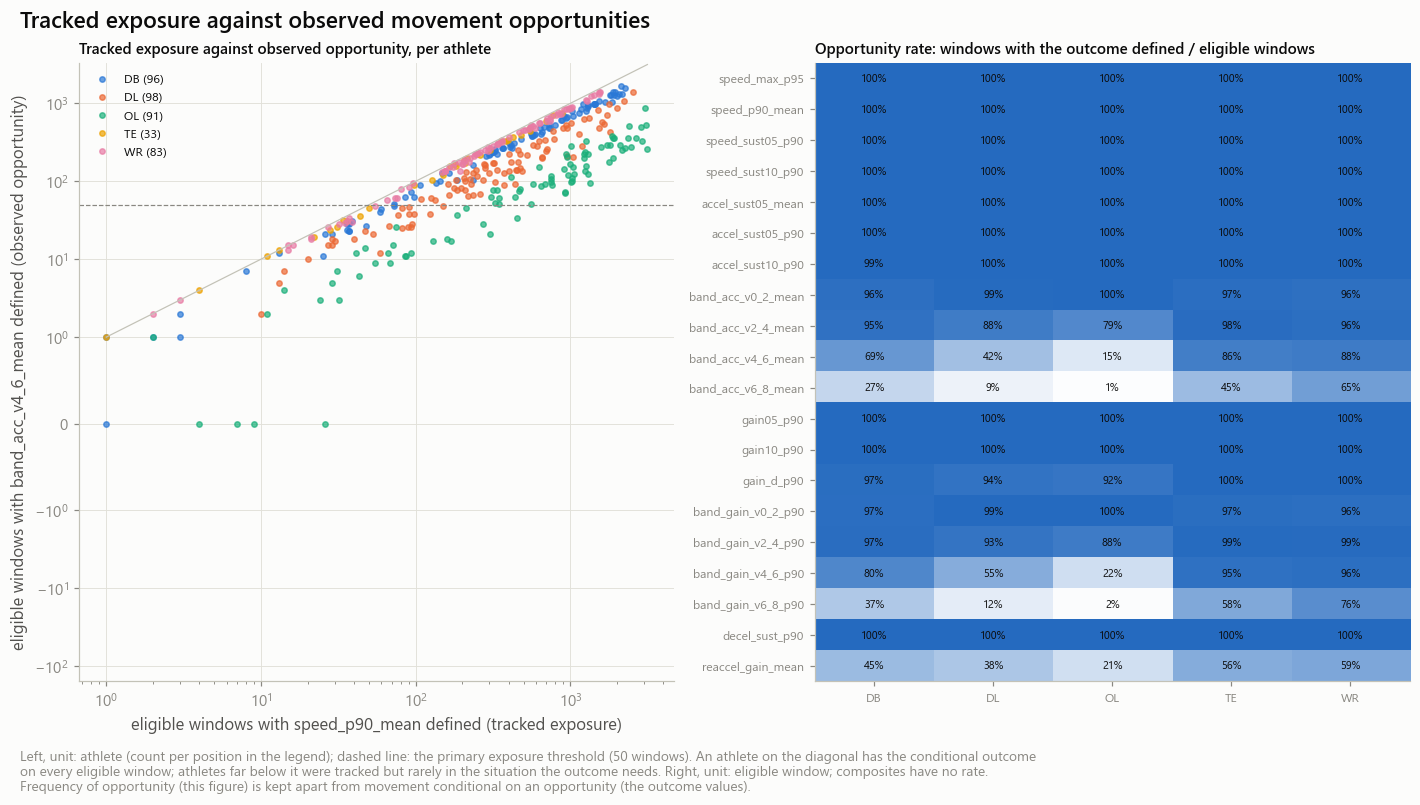

In [11]:
def build_athlete_level() -> dict:
    engine = no.OutcomeEngine(plays, c)
    values = no.athlete_outcomes(engine)
    return {no.DICTIONARY.name: no.outcome_dictionary(c), no.ATHLETE_OUTCOMES.name: values,
            no.ATHLETE_GAMES.name: no.athlete_game_outcomes(engine), COVERAGE.name: no.coverage_table(engine, values)}


athlete_level = store.build('NFL_ATHLETE', [no.DICTIONARY, no.ATHLETE_OUTCOMES, no.ATHLETE_GAMES, COVERAGE], build_athlete_level,
                            params=c.params(), files=[store.parquet(PLAYS)])
dictionary, outcomes, athlete_games, coverage = (athlete_level[k.name] for k in (no.DICTIONARY, no.ATHLETE_OUTCOMES, no.ATHLETE_GAMES, COVERAGE))
GE = f'n_athletes_ge_{c.primary_min_windows}'
display(Markdown(f'**Coverage, all positions** (unit: athlete; primary exposure threshold {c.primary_min_windows} windows)'))
with pl.Config(tbl_rows=60, float_precision=3):
    display(coverage.filter(pl.col('position_group') == no.ALL)
            .select('outcome_id', 'n_athletes_tracked', 'n_athletes_any', GE, 'n_windows', 'n_athlete_games', 'n_plays_undefined',
                    'opportunity_rate', 'rho_value_log_windows'))
display(Markdown(f'**Athletes at the primary threshold, by position group** (unit: athlete with ≥ {c.primary_min_windows} windows on the outcome)'))
with pl.Config(tbl_rows=60):
    display(coverage.filter(pl.col('position_group') != no.ALL).pivot(on='position_group', index='outcome_id', values=GE).sort('outcome_id'))
BASE_ID, COND_ID = 'O1.speed_p90_mean', f'O3.band_acc_{BANDS[min(2, len(BANDS) - 1)]}_mean'
store.show(nf.plot_exposure_vs_opportunity(outcomes, coverage, BASE_ID, COND_ID, c), 'AM05A_12_tracked_exposure_vs_opportunity',
           {'coverage': coverage}, publication=True, source='nfl_athlete_outcomes, nfl_outcome_coverage', n=f'{n_athletes} athletes')
FIGURES += ['AM05A_12_tracked_exposure_vs_opportunity']

## 10 · Within-athlete game variation

For two measures — a speed and an acceleration — the athlete-game means of each athlete against the spread between athletes. This is the picture behind the reliability numbers of 05B: when an athlete's games range as widely as the athletes differ, a few games cannot rank athletes.

**Spread between athletes against spread of an athlete over games** (unit: athlete with ≥ 4 games; play measure of the outcome, athlete-game means)

outcome_id,position_group,athletes,median_games,sd_between_athletes,median_sd_of_an_athletes_games
str,str,u32,f64,f64,f64
"""O1.speed_sust10_p90""","""DB""",75,17.000,0.269,0.395
"""O1.speed_sust10_p90""","""DL""",90,17.000,0.426,0.399
"""O1.speed_sust10_p90""","""OL""",75,17.000,0.272,0.223
"""O1.speed_sust10_p90""","""TE""",27,21.000,0.336,0.460
"""O1.speed_sust10_p90""","""WR""",73,19.000,0.449,0.474
"""O2.accel_sust05_p90""","""DB""",75,17.000,0.185,0.293
"""O2.accel_sust05_p90""","""DL""",89,17.000,0.440,0.273
"""O2.accel_sust05_p90""","""OL""",75,17.000,0.219,0.178
"""O2.accel_sust05_p90""","""TE""",27,21.000,0.241,0.355


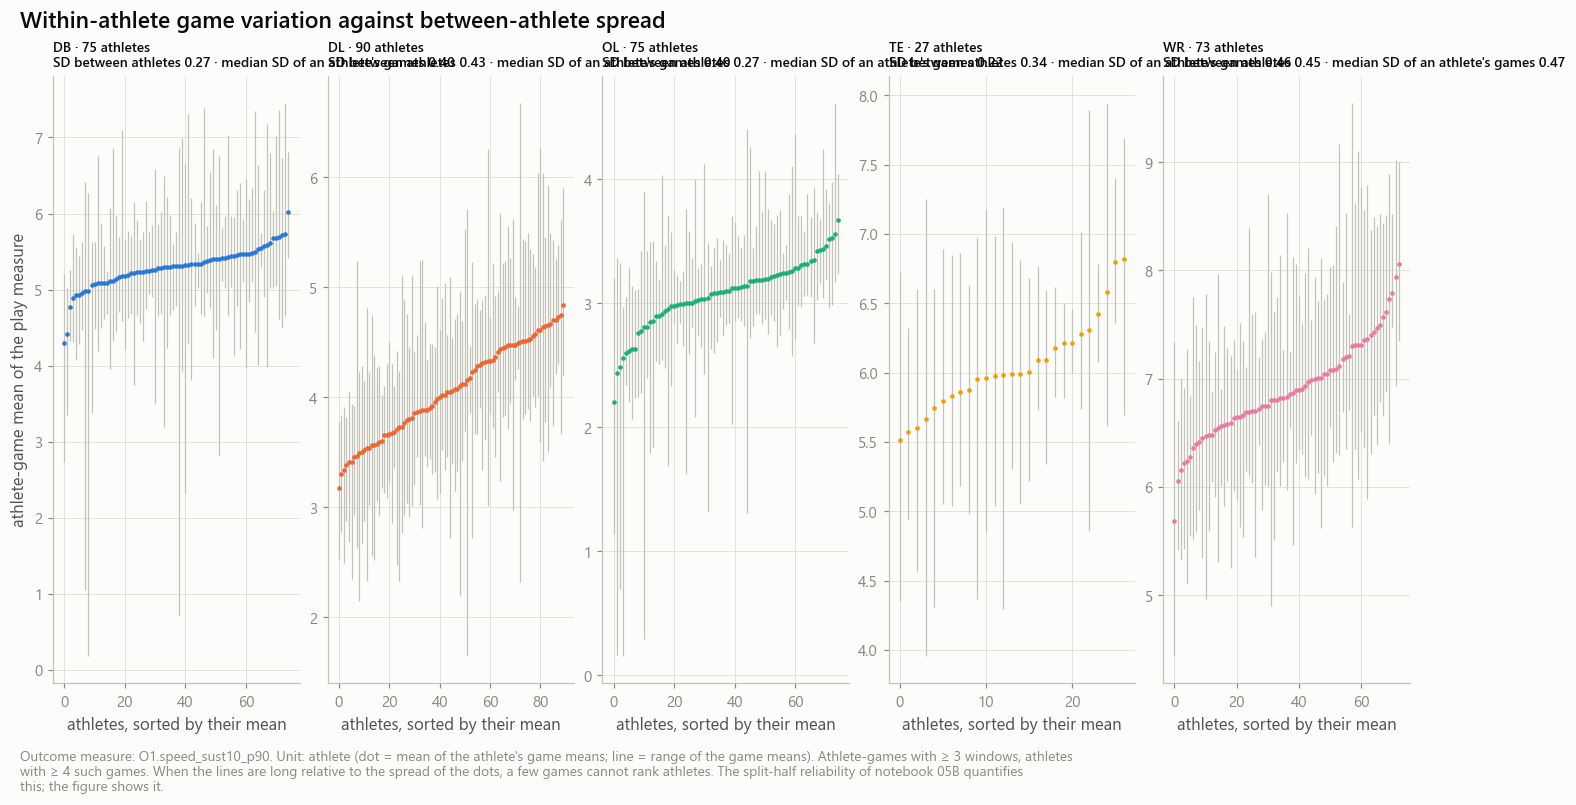

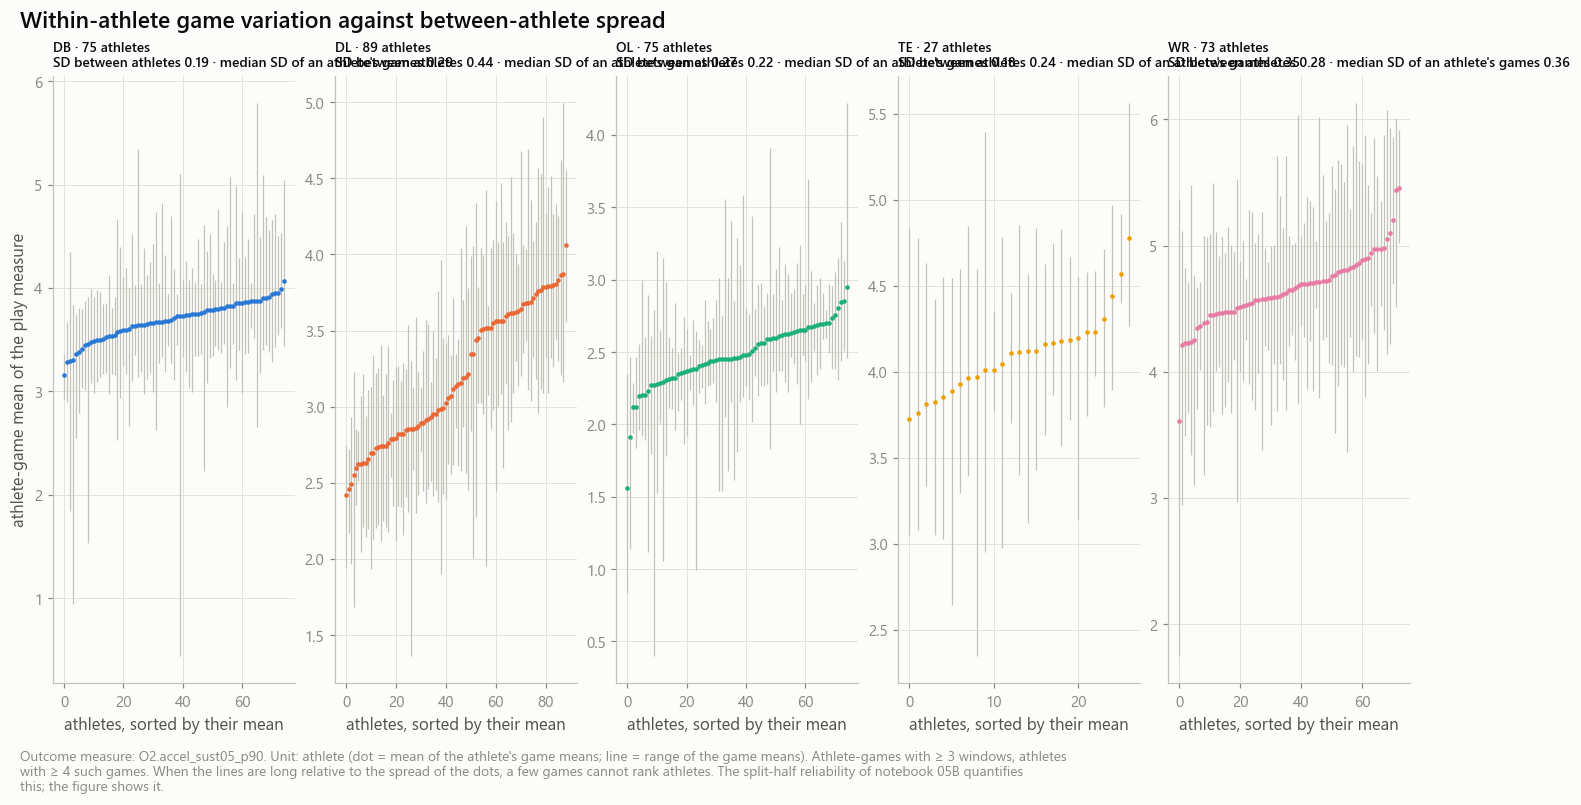

In [12]:
position_of = el.select('nfl_id', 'position_group').unique(subset='nfl_id')
GAME_OUTCOMES = [f'O1.speed_sust{L1}_p90', f'O2.accel_sust{L0}_p90']
game_spread = (athlete_games.filter(pl.col('outcome_id').is_in(GAME_OUTCOMES) & (pl.col('n_windows') >= c.min_game_windows))
               .join(position_of, on='nfl_id').group_by('outcome_id', 'position_group', 'nfl_id')
               .agg(pl.len().alias('games'), pl.col('mean').mean().alias('athlete_mean'), pl.col('mean').std().alias('game_sd'))
               .filter(pl.col('games') >= 4).group_by('outcome_id', 'position_group')
               .agg(pl.len().alias('athletes'), pl.col('games').median().alias('median_games'), pl.col('athlete_mean').std().alias('sd_between_athletes'),
                    pl.col('game_sd').median().alias('median_sd_of_an_athletes_games')).sort('outcome_id', 'position_group'))
display(Markdown('**Spread between athletes against spread of an athlete over games** (unit: athlete with ≥ 4 games; play measure of the outcome, athlete-game means)'))
with pl.Config(tbl_rows=40, float_precision=3):
    display(game_spread)
for k, oid in enumerate(GAME_OUTCOMES):
    name = f'AM05A_08{"ab"[k]}_game_vs_athlete_variability'
    store.show(nf.plot_game_vs_athlete(athlete_games, oid, position_of, c), name, {'game_spread': game_spread.filter(pl.col('outcome_id') == oid)},
               publication=k == 0, source='nfl_athlete_game_outcomes', n=f'{n_athletes} athletes')
    FIGURES += [name]

## 11 · Smoothing, boundaries and missingness

The same windows under other filters and with filter-edge windows kept. A second derivative carries the most filter noise, and a *maximum* over windows rises with noise (the synthetic check of section 2 shows it on an analytic trajectory), so the level of the acceleration measures is expected to move with the filter more than the level of the speed measures. Whether the *ranking of athletes* survives is tested in 05B.

The right-hand figure shows what is excluded and what is undefined. Undefined measures are kept missing.

**Play-level agreement of each variant with the primary measure** (unit: eligible window computed under both)

variant,measure,n_windows,pearson,mean_shift,shift_sd_units,sd_ratio
str,str,i64,f64,f64,f64,f64
"""boundary_incl""","""accel_sust05""",125261,0.999,0.003,0.002,0.998
"""sg11p3""","""accel_sust05""",125220,0.995,-0.193,-0.157,0.965
"""sg5p2""","""accel_sust05""",125253,0.998,0.083,0.067,1.014
"""sg9p2""","""accel_sust05""",125233,0.999,-0.085,-0.069,0.983
"""boundary_incl""","""accel_sust10""",124999,0.999,0.003,0.002,0.998
"""sg11p3""","""accel_sust10""",124868,0.997,-0.122,-0.109,0.974
"""sg5p2""","""accel_sust10""",124986,0.999,0.040,0.036,1.010
"""sg9p2""","""accel_sust10""",124958,0.999,-0.044,-0.040,0.987
"""boundary_incl""","""band_acc_v0_2""",122748,0.990,-0.046,-0.042,0.985


**First failing eligibility rule** (unit: tracked player-play; an empty reason = eligible)

position_group,exclusion_reason,player_plays,athletes
str,str,u32,u32
"""DB""","""""",63914,96
"""DB""","""nullified_by_penalty""",2889,84
"""DB""","""quality_tier_not_usable""",73,37
"""DB""","""short_post_snap_window""",6,6
"""DL""","""""",50363,98
"""DL""","""nullified_by_penalty""",2179,92
"""DL""","""quality_tier_not_usable""",23,15
"""DL""","""short_post_snap_window""",19,18
"""OL""","""""",82806,91


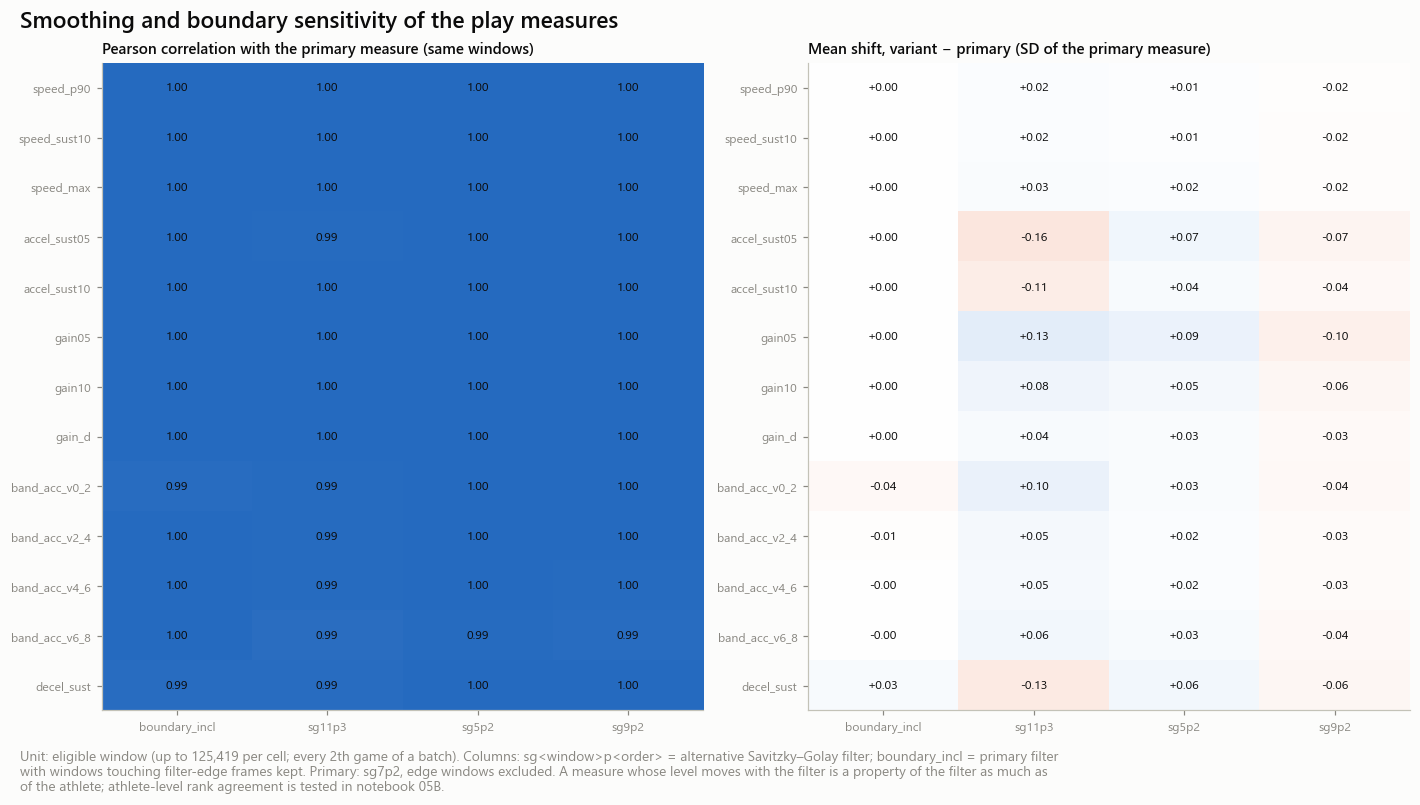

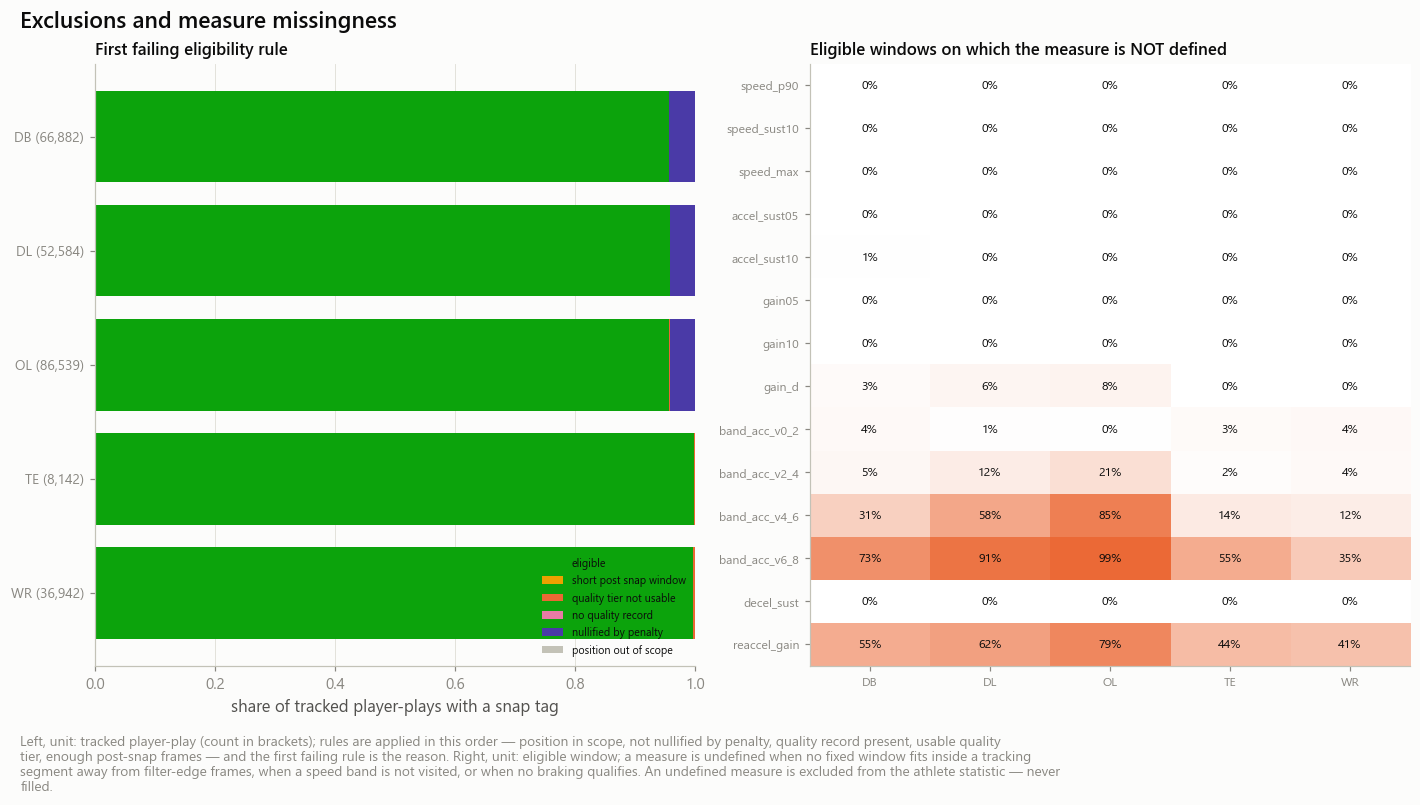

In [13]:
SENS_MEASURES = [*SPEED_MEASURES, *ACCEL_MEASURES, 'gain_d', *BAND_MEASURES, 'decel_sust']
agreement = nf.variant_play_agreement(plays, variants, SENS_MEASURES)
display(Markdown('**Play-level agreement of each variant with the primary measure** (unit: eligible window computed under both)'))
with pl.Config(tbl_rows=80, float_precision=3):
    display(agreement.sort('measure', 'variant'))
reasons = (plays.with_columns(pl.col('position_group').fill_null('UNKNOWN')).group_by('position_group', 'exclusion_reason')
           .agg(pl.len().alias('player_plays'), pl.col('nfl_id').n_unique().alias('athletes')).sort('position_group', 'exclusion_reason'))
display(Markdown('**First failing eligibility rule** (unit: tracked player-play; an empty reason = eligible)'))
with pl.Config(tbl_rows=60):
    display(reasons)
if controls.save_tables:
    agreement.write_csv(store.tables_dir / 'nfl_play_variant_agreement.csv')
    reasons.write_csv(store.tables_dir / 'nfl_exclusion_reasons.csv')
store.show(nf.plot_smoothing_sensitivity(agreement, c), 'AM05A_09_smoothing_and_boundary_sensitivity', {'agreement': agreement},
           publication=True, source='nfl_play_movement, nfl_play_movement_variants',
           n=f'{int(agreement["n_windows"].max()) if agreement.height else 0} windows')
store.show(nf.plot_exclusions_missingness(plays, [*SENS_MEASURES, 'reaccel_gain'], c), 'AM05A_10_exclusions_and_missingness',
           {'reasons': reasons}, source='nfl_play_movement', n=f'{plays.height} player-plays')
FIGURES += ['AM05A_09_smoothing_and_boundary_sensitivity', 'AM05A_10_exclusions_and_missingness']

## 12 · Example recorded movement

Real player-plays, chosen by rule: for each position group, the eligible window whose 1.0 s sustained speed is closest to the median and to the 90th percentile of that group. The frames are recomputed from the silver tracking with the primary filter. Each panel shows the speed, the tangential acceleration, the filter-edge frames and the 0.5 s window with the largest speed gain.

**Example windows** (chosen by rule: closest to the stated quantile of the position group)

position_group,quantile,game_id,play_id,nfl_id,value
str,f64,i64,i64,i64,f64
"""DB""",0.5,2025100506,170,55948,5.230391
"""DB""",0.9,2025101300,565,57181,7.494044
"""DL""",0.5,2025091409,2586,57148,4.032019
"""DL""",0.9,2025110909,1514,57140,6.070147
"""OL""",0.5,2024120804,2733,55878,3.014282
"""OL""",0.9,2025091800,310,57176,4.581748
"""TE""",0.5,2024102007,639,57228,6.098099
"""TE""",0.9,2024112408,3292,55943,7.600298
"""WR""",0.5,2025090701,2599,55939,6.933974


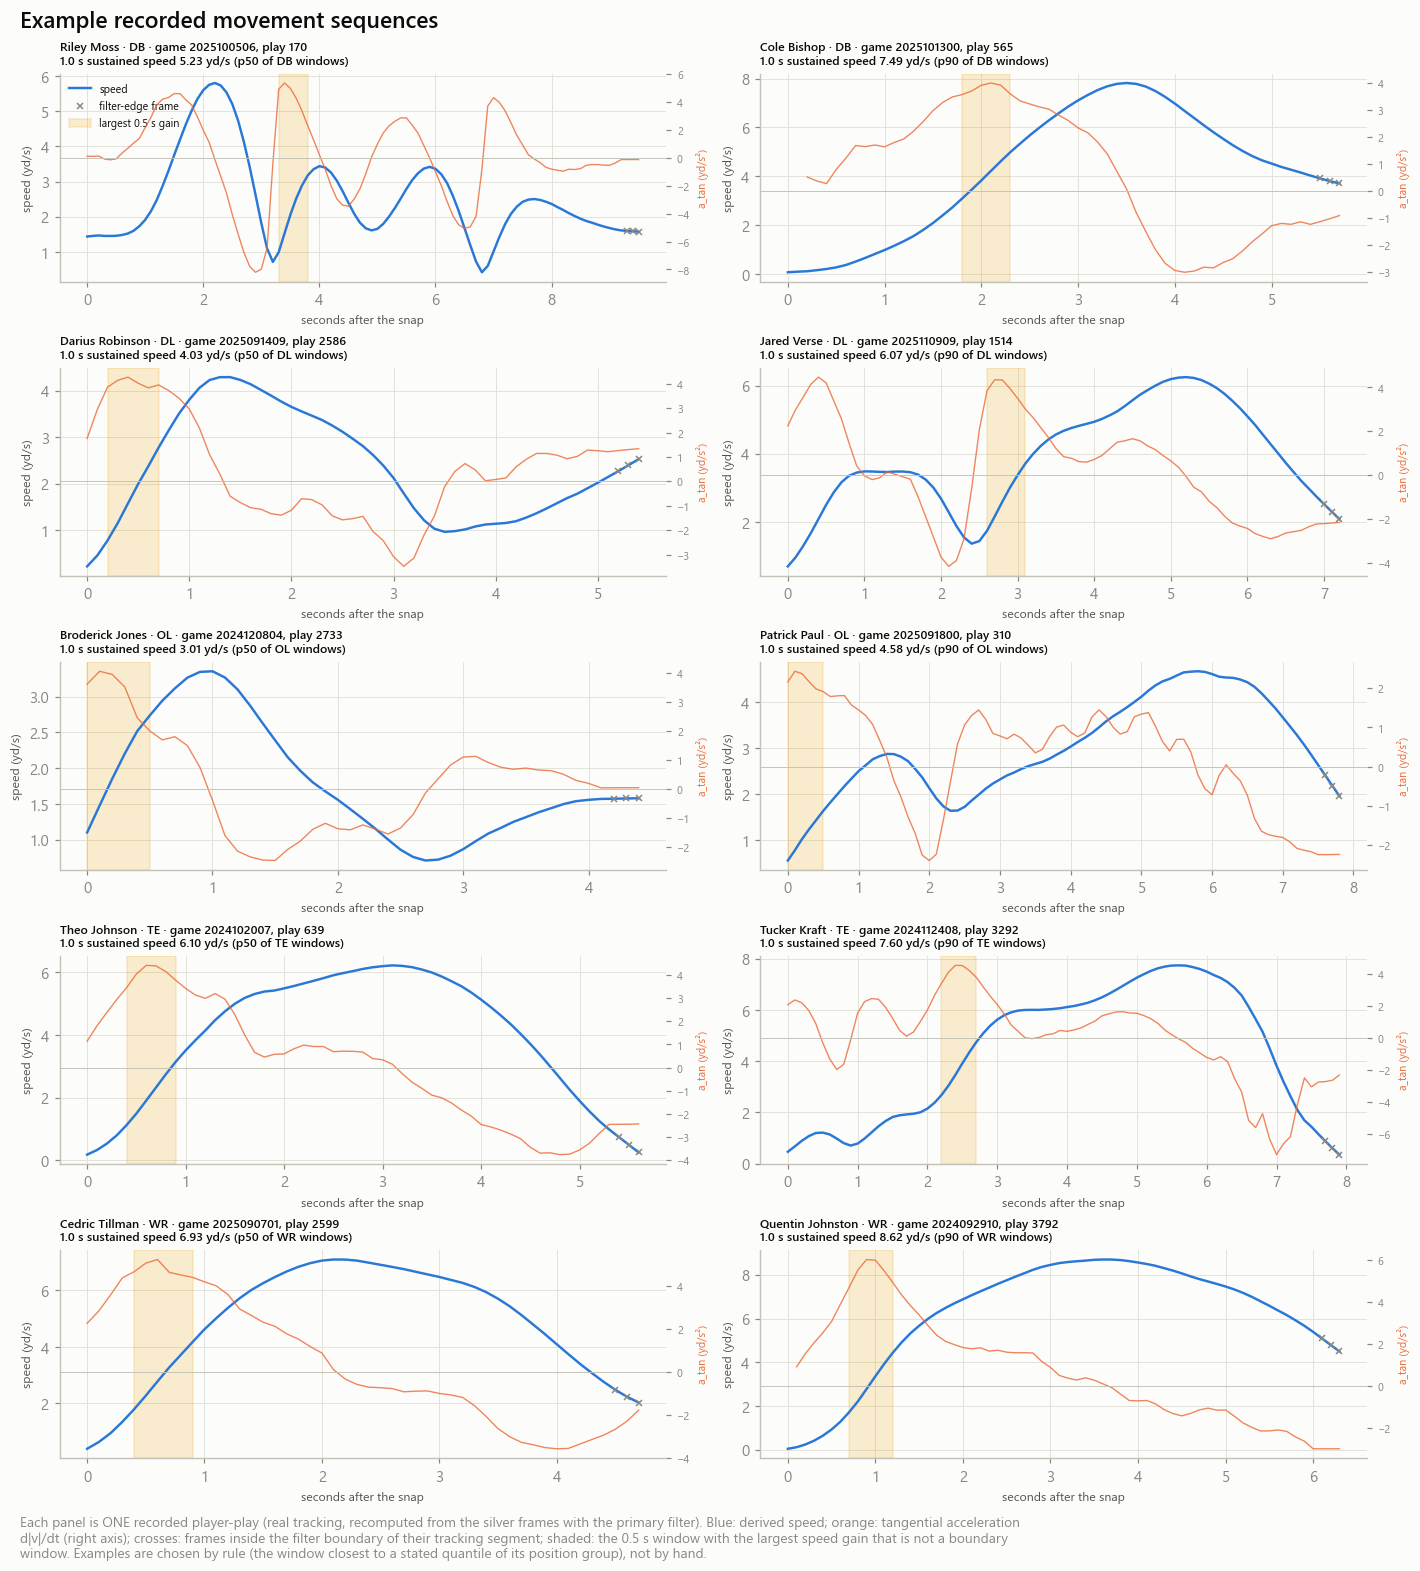

In [14]:
EXAMPLE_MEASURE, EXAMPLE_QUANTILES = f'speed_sust{L1}', (0.5, 0.9)
examples = no.example_plays(plays, EXAMPLE_MEASURE, POSITIONS, EXAMPLE_QUANTILES)
names = dict(builder.refs.scan('gold', 'dim_athlete').select(pl.col('nfl_id').cast(pl.Int64), pl.col('display_name').cast(pl.String)).collect().iter_rows())
items = []
for r in examples.iter_rows(named=True):
    who, pos, q, val = names.get(r['nfl_id'], r['nfl_id']), r['position_group'], int(100 * r['quantile']), r['value']
    game, play = r['game_id'], r['play_id']
    items.append({'frames': builder.example_frames(game, play, r['nfl_id']),
                  'title': f'{who} · {pos} · game {game}, play {play}\n1.0 s sustained speed {val:.2f} yd/s (p{q} of {pos} windows)'})
display(Markdown('**Example windows** (chosen by rule: closest to the stated quantile of the position group)'))
display(examples)
store.show(nf.plot_examples(items, len(EXAMPLE_QUANTILES), c), 'AM05A_11_example_movement_sequences', {'examples': examples},
           publication=True, source='silver.game_tracking (recomputed), nfl_play_movement', n=f'{len(items)} recorded player-plays',
           note='real recorded movement; selection by rule')
FIGURES += ['AM05A_11_example_movement_sequences']

## 13 · Reading generated from the tables

The statements below are computed from the tables of this run. In smoke mode they are a wiring check and must not be read as findings.

In [15]:
lines = ['### What the tables of this run show', '']
if controls.smoke:
    lines += ['**SMOKE RUN — technical check only. Do not interpret any number below.**', '']
elig = funnel.filter((pl.col('position_group') == no.ALL)).sort('stage_order')
first_n, last_n = elig['n_player_plays'][0], elig['n_player_plays'][-1]
lines.append(f'- {last_n:,} of {first_n:,} tracked player-plays with a snap tag are eligible ({last_n / max(first_n, 1):.1%}); '
             f'{n_athletes} athletes, {n_games:,} athlete-games.')
cand = dictionary.filter(pl.col('role') == 'candidate')['outcome_id'].to_list()
cov_all = coverage.filter((pl.col('position_group') == no.ALL) & pl.col('outcome_id').is_in(cand)).sort(GE, descending=True)
for r in cov_all.iter_rows(named=True):
    oid, n_ge, tracked, rate, rho = r['outcome_id'], r[GE], r['n_athletes_tracked'], r['opportunity_rate'], r['rho_value_log_windows']
    rate_txt = 'composite' if rate is None else f'opportunity rate {rate:.2f}'
    rho_txt = 'n/a' if rho is None else f'{rho:+.2f}'
    lines.append(f'- `{oid}`: {n_ge} of {tracked} tracked athletes reach {c.primary_min_windows} windows; {rate_txt}; '
                 f'rank correlation of the value with log exposure {rho_txt}.')
per_pos = coverage.filter((pl.col('position_group') != no.ALL) & pl.col('outcome_id').is_in(cand) & (pl.col(GE) < c.min_athletes_position))
if per_pos.height:
    thin = ', '.join(f'{o} in {p} ({n})' for o, p, n in per_pos.select('outcome_id', 'position_group', GE).iter_rows())
    lines.append(f'- Outcome × position cells with fewer than {c.min_athletes_position} athletes at the threshold (no within-position estimate '
                 f'possible there): {thin}.')
worst = (agreement.filter(pl.col('variant').str.starts_with('sg') & pl.col('pearson').is_not_nan() & pl.col('shift_sd_units').is_not_null())
         .sort('pearson').head(3))
for r in worst.iter_rows(named=True):
    m, v, rr, sh = r['measure'], r['variant'], r['pearson'], r['shift_sd_units']
    lines.append(f'- Lowest play-level agreement across filters: `{m}` under {v}, Pearson {rr:.3f}, mean shift {sh:+.2f} SD.')
lines += ['', 'None of these statements uses a Combine value. Reliability across games, exposure curves and the freeze decision are in notebook 05B.']
reading = '\n'.join(lines)
display(Markdown(reading))

### What the tables of this run show

- 242,043 of 251,089 tracked player-plays with a snap tag are eligible (96.4%); 401 athletes, 7,891 athlete-games.
- `O1.speed_sust05_p90`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure -0.09.
- `O1.speed_sust10_p90`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure -0.09.
- `O1.speed_p90_mean`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure -0.09.
- `O2.accel_sust05_p90`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure +0.13.
- `O2.accel_sust10_p90`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure +0.09.
- `O2.accel_sust05_mean`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure +0.11.
- `O3.band_acc_v0_2_mean`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 0.98; rank correlation of the value with log exposure -0.02.
- `O4.gain05_p90`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure +0.12.
- `O4.gain10_p90`: 336 of 401 tracked athletes reach 50 windows; opportunity rate 1.00; rank correlation of the value with log exposure +0.09.
- `O4.gain_d_p90`: 334 of 401 tracked athletes reach 50 windows; opportunity rate 0.95; rank correlation of the value with log exposure +0.02.
- `O3.band_acc_v2_4_mean`: 333 of 401 tracked athletes reach 50 windows; opportunity rate 0.88; rank correlation of the value with log exposure +0.04.
- `O3.band_acc_v4_6_mean`: 301 of 401 tracked athletes reach 50 windows; opportunity rate 0.49; rank correlation of the value with log exposure +0.04.
- `O5.envelope_level`: 207 of 401 tracked athletes reach 50 windows; composite; rank correlation of the value with log exposure +0.17.
- `O3.band_acc_v6_8_mean`: 183 of 401 tracked athletes reach 50 windows; opportunity rate 0.21; rank correlation of the value with log exposure +0.05.
- Outcome × position cells with fewer than 15 athletes at the threshold (no within-position estimate possible there): O3.band_acc_v6_8_mean in OL (1), O5.envelope_level in OL (9).
- Lowest play-level agreement across filters: `band_acc_v6_8` under sg11p3, Pearson 0.988, mean shift +0.06 SD.
- Lowest play-level agreement across filters: `decel_sust` under sg11p3, Pearson 0.990, mean shift -0.13 SD.
- Lowest play-level agreement across filters: `band_acc_v6_8` under sg9p2, Pearson 0.991, mean shift -0.04 SD.

None of these statements uses a Combine value. Reliability across games, exposure curves and the freeze decision are in notebook 05B.

## 14 · Outputs and manifest

In [16]:
manifest = {'notebook': NB05A, 'status': 'executed', 'definition_hash': no.definition_hash(c), 'outcomes_version': c.version,
            'config': c.params(), 'kinematics': builder.kcfg.params(), 'seed': controls.seed, 'limit_games': builder.limit_games,
            'athlete_subset': athlete_ids, 'n_player_plays': plays.height, 'n_eligible_windows': el.height, 'n_athletes': n_athletes,
            'n_athlete_games': n_games, 'positions': POSITIONS, 'figures': FIGURES, 'validation': validation_report.to_dicts(),
            'inputs': {cfg.paths.rel(f): file_fingerprint(f) for f in builder.input_files()}}
if controls.save_tables:
    store.write_json('nfl_outcome_manifest', manifest)
    (store.tables_dir / 'nfl_outcome_eda_reading.md').write_text(reading, encoding='utf-8')
listing = []
for kind, folder, pattern in (('table (CSV)', store.tables_dir, '*.csv'), ('dataset (Parquet)', store.data_dir, '*.parquet'),
                              ('metadata (JSON)', store.data_dir, 'nfl_*.json'), ('figure (PNG)', store.figures_dir, '*.png')):
    for f in (sorted(folder.glob(pattern)) if folder.is_dir() else []):
        listing.append({'kind': kind, 'file': cfg.paths.rel(f), 'size_kb': round(f.stat().st_size / 1024, 1)})
with pl.Config(tbl_rows=80, fmt_str_lengths=140):
    display(pl.DataFrame(listing, schema={'kind': pl.String, 'file': pl.String, 'size_kb': pl.Float64}))

kind,file,size_kb
str,str,f64
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_exclusion_reasons.csv""",0.5
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_coverage.csv""",13.7
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_dictionary.csv""",17.7
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_play_measure_summary.csv""",9.2
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_play_variant_agreement.csv""",5.4
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_window_funnel.csv""",1.2
"""dataset (Parquet)""","""warehouse/gold/advanced_movement/nfl_outcomes/nfl_athlete_game_outcomes.parquet""",2238.8
"""dataset (Parquet)""","""warehouse/gold/advanced_movement/nfl_outcomes/nfl_athlete_outcomes.parquet""",144.5
"""dataset (Parquet)""","""warehouse/gold/advanced_movement/nfl_outcomes/nfl_outcome_coverage.parquet""",10.6


## 15 · Limitations and next decision

**Limitations that no table of this notebook removes.**

- **Role and opportunity.** The measures describe movement that occurred. Assignment, opponent, scheme, route and pass-rush opportunity are not recorded; alignment, play class, side and down are the only context labels. A comparison of athletes is a comparison of athletes *in their observed usage*.
- **Selected population.** Only Combine-cohort athletes are tracked, and the athletes with many windows are those who played. Thresholds on exposure select them further.
- **Play class is inferred** from the vendor `pass_result` code; the meaning of the empty code is not confirmed.
- **Maxima rise with noise.** Every play measure is a maximum over windows. A noisier filter or a longer play gives a larger maximum without more movement. Section 11 shows the size of the filter effect at play level.
- **Filter choice.** The primary filter is the project's established one; it was not tuned here, and no filter is chosen with an outcome.
- **Braking and re-acceleration (O6)** rest on a provisional threshold and no validated manoeuvre label; contact and the end of a play produce decelerations that are not braking. They stay exploratory.
- **The vendor get-off field is not used**; its definition is still unresolved.

**Next decision.** Run notebook `05b_nfl_outcome_reliability_and_freeze.ipynb` in the same `RUN_MODE`. It measures the reliability of each candidate across independent games, at fixed observation budgets, under context adjustment and under alternative filters, and records the freeze decision (`FREEZE` with one primary and at most two secondary outcomes, or `STOP`). No Combine association is consulted before that decision is written.